# Examining Sub-Research Research Question 3: Language

The third sub-research question is as follows: **'Are there differences in content between homosexual and heterosexual fan fiction on Archive of Our Own, regarding variables such as the language, date published, or word count?**

In [116]:
# Import package
import polars as pl
import pyarrow
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_metadata = pl.read_ndjson("./data/combined_metadata.jsonl") # Create the df_metadata DataFrame
df_metadata = df_metadata.unnest('metadata') # Turn the metadata column into 18 separate columns

fandoms = ["DC's Legends of Tomorrow (TV)", "Avatar: The Last Airbender (Cartoon 2005)", "Spider-Man: Spider-Verse (Sony Animated Movies)"]

# Select the target fandom and relationship categories
df_metadata = df_metadata.filter(
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]) |
    (pl.col("Fandom") == fandoms[2])) &
    ((pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M") |
    (pl.col("Category") == "F/M"))
)

df_metadata.head()

id,title,Additional Tags,Archive Warning,Category,Characters,Fandoms,Language,Rating,Relationship,author,chapters,completed,published,words,Fandom,Character,Collections,Series,Relationships
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""10012010""","""Just One Training""","""Explicit Sexual Content, Oral …","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""Explicit""","""Sara Lance/Leonard Snart""","""by capnwho""","""1/1""","""""","""2017-02-28""","""1,470""","""DC's Legends of Tomorrow (TV)""",null,null,"""Just One Fixation""",null
"""10013705""","""Five Months More""","""Established Relationship, surp…","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart""",null,"""English""","""Not Rated""",null,"""by flabbergabst""","""1/1""","""""","""2017-02-28""","""505""","""DC's Legends of Tomorrow (TV)""",null,null,"""The Captain Canary Collection""","""Sara Lance/Leonard Snart, Capt…"
"""10018964""","""It Ends with a Kiss""","""Alpha/Beta/Omega Dynamics, Min…","""No Archive Warnings Apply""","""M/M""","""Leonard Snart, Ray Palmer, Mic…",null,"""English""","""Teen And Up Audiences""","""Ray Palmer/Leonard Snart""","""by Constantsnow""","""1/1""","""""","""2017-02-28""","""3,008""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10030784""","""Bet""",null,"""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""General Audiences""","""Sara Lance/Leonard Snart""","""by orphan_account""","""1/1""","""""","""2017-03-01""","""1,273""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10033958""","""For the Both of Us""","""Captain Canary, ficcingcaptain…","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""Not Rated""",null,"""by flabbergabst""","""1/1""","""""","""2017-03-01""","""1,067""","""DC's Legends of Tomorrow (TV)""",null,null,"""The Captain Canary Collection""","""Sara Lance/Leonard Snart, Capt…"


In [143]:
# Change all language names to English
language_names = {
    "Español": "Spanish",
    "中文-普通话 國語": "Mandarin",
    "Русский": "Russian",
    "Français": "French",
    "Português brasileiro": "Brazilian Portuguese",
    "Bahasa Indonesia": "Indonesian",
    "Українська": "Ukrainian",
    "Italiano": "Italian",
    "Polski": "Polish",
    "Tiếng Việt": "Vietnamese",
    "беларуская": "Belarusian",
    "العربية": "Arabic",
    "日本語": "Japanese",
    "Čeština": "Czech",
    "Türkçe": "Turkish",
    "Deutsch": "German",
    "Català": "Catalan"
}

df_metadata = df_metadata.with_columns(
    pl.col("Language").replace(language_names)
)

In [144]:
ff_mm_language_amt = df_metadata.filter(
    (pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")
).select(pl.col("Language").value_counts()).unnest("Language").sort("count", descending=True)

fm_language_amt = df_metadata.filter(
    (pl.col("Category") == "F/M")
).select(pl.col("Language").value_counts()).unnest("Language").sort("count", descending=True)

print("Homosexual Fan Works Amount:")
ff_mm_language_amt.show(17)
print("Heterosexual Fan Works Amount:")
fm_language_amt.show(13)

ff_mm_language_list = ff_mm_language_amt.to_series(0).to_list()
fm_language_list = fm_language_amt.to_series(0).to_list()

print("Homosexual Languages: ", ff_mm_language_list)
print("Heterosexual Languages: ", fm_language_list)

Homosexual Fan Works Amount:


Language,count
str,u32
"""English""",5252
"""Mandarin""",207
"""Spanish""",127
"""Russian""",38
"""French""",30
"""Brazilian Portuguese""",14
"""Vietnamese""",12
"""Ukrainian""",10
"""Italian""",7


Heterosexual Fan Works Amount:


Language,count
str,u32
"""English""",4142
"""Spanish""",42
"""Russian""",26
"""Mandarin""",26
"""French""",7
"""Brazilian Portuguese""",3
"""Ukrainian""",2
"""Indonesian""",2
"""Italian""",2


Homosexual Languages:  ['English', 'Mandarin', 'Spanish', 'Russian', 'French', 'Brazilian Portuguese', 'Vietnamese', 'Ukrainian', 'Italian', 'Japanese', 'Czech', 'Catalan', 'Indonesian', 'Arabic', 'Polish', 'Turkish', 'German']
Heterosexual Languages:  ['English', 'Spanish', 'Russian', 'Mandarin', 'French', 'Brazilian Portuguese', 'Ukrainian', 'Indonesian', 'Italian', 'Arabic', 'Belarusian', 'Vietnamese', 'Polish']


## 1. Ratings

### 1.1 Creating the Ratings Datasets

In [168]:
# Filtered by F/F + M/M based on language
df_ff_mm_languages_ratings = pl.DataFrame()
for ff_mm_language in ff_mm_language_list:
    ff_mm_language_ratings = df_metadata.filter(
        ((pl.col("Category") == "F/F") |
        (pl.col("Category") == "M/M")) &
        (pl.col("Language") == ff_mm_language)
    ).select(pl.col("Rating").value_counts()).unnest("Rating").sort("Rating").unpivot(index="Rating", variable_name="count").pivot("Rating", index="count").drop("count").with_columns(pl.lit(ff_mm_language).alias("Language")) # Filter based on language
    df_ff_mm_languages_ratings = pl.concat([df_ff_mm_languages_ratings, ff_mm_language_ratings], how="diagonal") # Concatenate the DataFrames

df_ff_mm_languages_ratings = df_ff_mm_languages_ratings.select(['Language', 'Not Rated', 'General Audiences', 'Teen And Up Audiences', 'Mature', 'Explicit']) # Reorder the columns
df_ff_mm_languages_ratings = df_ff_mm_languages_ratings.with_columns(pl.all().fill_null(strategy="zero"))

# Filtered by F/M based on language
df_fm_languages_ratings = pl.DataFrame()
for fm_language in fm_language_list:
    fm_language_ratings = df_metadata.filter(
        (pl.col("Category") == "F/M") &
        (pl.col("Language") == fm_language)
    ).select(pl.col("Rating").value_counts()).unnest("Rating").sort("Rating").unpivot(index="Rating", variable_name="count").pivot("Rating", index="count").drop("count").with_columns(pl.lit(fm_language).alias("Language")) # Filter based on language
    df_fm_languages_ratings = pl.concat([df_fm_languages_ratings, fm_language_ratings], how="diagonal") # Concatenate the DataFrames

df_fm_languages_ratings = df_fm_languages_ratings.select(['Language', 'Not Rated', 'General Audiences', 'Teen And Up Audiences', 'Mature', 'Explicit']) # Reorder the columns
df_fm_languages_ratings = df_fm_languages_ratings.with_columns(pl.all().fill_null(strategy="zero"))

print("Homosexual Language Ratings Amount:")
df_ff_mm_languages_ratings.show(17)
print("Heterosexual Language Ratings Amount:")
df_fm_languages_ratings.show(13)

# Calculate the Ratings percentage distribution per language
df_ff_mm_languages_percentages_ratings = df_ff_mm_languages_ratings.with_columns(
    (pl.col("Not Rated") / pl.sum_horizontal(pl.exclude("Language")) * 100).alias("Not Rated"),
    (pl.col("General Audiences") / pl.sum_horizontal(pl.exclude("Language")) * 100).alias("General Audiences"),
    (pl.col("Teen And Up Audiences") / pl.sum_horizontal(pl.exclude("Language")) * 100).alias("Teen And Up Audiences"), (pl.col("Mature") / pl.sum_horizontal(pl.exclude("Language")) * 100).alias("Mature"),
    (pl.col("Explicit") / pl.sum_horizontal(pl.exclude("Language")) * 100).alias("Explicit")).with_columns(pl.exclude("Language").round(2)) # Filtered by F/F + M/M
df_fm_languages_percentages_ratings = df_fm_languages_ratings.with_columns(
    (pl.col("Not Rated") / pl.sum_horizontal(pl.exclude("Language")) * 100).alias("Not Rated"),
    (pl.col("General Audiences") / pl.sum_horizontal(pl.exclude("Language")) * 100).alias("General Audiences"),
    (pl.col("Teen And Up Audiences") / pl.sum_horizontal(pl.exclude("Language")) * 100).alias("Teen And Up Audiences"), (pl.col("Mature") / pl.sum_horizontal(pl.exclude("Language")) * 100).alias("Mature"),
    (pl.col("Explicit") / pl.sum_horizontal(pl.exclude("Language")) * 100).alias("Explicit")).with_columns(pl.exclude("Language").round(2)) # Filtered by F/M

print("Homosexual Language Ratings Percentage Distribution:")
df_ff_mm_languages_percentages_ratings.show(17)
print("Heterosexual Language Ratings Percentage Distribution:")
df_fm_languages_percentages_ratings.show(13)

Homosexual Language Ratings Amount:


Language,Not Rated,General Audiences,Teen And Up Audiences,Mature,Explicit
str,u32,u32,u32,u32,u32
"""English""",482,1271,1707,732,1060
"""Mandarin""",45,32,22,58,50
"""Spanish""",14,17,21,29,46
"""Russian""",1,9,13,5,10
"""French""",1,15,7,4,3
"""Brazilian Portuguese""",4,5,2,3,0
"""Vietnamese""",2,3,1,2,4
"""Ukrainian""",1,2,4,3,0
"""Italian""",0,4,3,0,0


Heterosexual Language Ratings Amount:


Language,Not Rated,General Audiences,Teen And Up Audiences,Mature,Explicit
str,u32,u32,u32,u32,u32
"""English""",381,1170,1191,605,795
"""Spanish""",1,15,9,6,11
"""Russian""",1,8,8,5,4
"""Mandarin""",7,3,5,5,6
"""French""",0,5,1,0,1
"""Brazilian Portuguese""",0,2,0,0,1
"""Ukrainian""",0,0,2,0,0
"""Indonesian""",0,1,1,0,0
"""Italian""",0,0,2,0,0


Homosexual Language Ratings Percentage Distribution:


Language,Not Rated,General Audiences,Teen And Up Audiences,Mature,Explicit
str,f64,f64,f64,f64,f64
"""English""",9.18,24.2,32.5,13.94,20.18
"""Mandarin""",21.74,15.46,10.63,28.02,24.15
"""Spanish""",11.02,13.39,16.54,22.83,36.22
"""Russian""",2.63,23.68,34.21,13.16,26.32
"""French""",3.33,50.0,23.33,13.33,10.0
"""Brazilian Portuguese""",28.57,35.71,14.29,21.43,0.0
"""Vietnamese""",16.67,25.0,8.33,16.67,33.33
"""Ukrainian""",10.0,20.0,40.0,30.0,0.0
"""Italian""",0.0,57.14,42.86,0.0,0.0


Heterosexual Language Ratings Percentage Distribution:


Language,Not Rated,General Audiences,Teen And Up Audiences,Mature,Explicit
str,f64,f64,f64,f64,f64
"""English""",9.2,28.25,28.75,14.61,19.19
"""Spanish""",2.38,35.71,21.43,14.29,26.19
"""Russian""",3.85,30.77,30.77,19.23,15.38
"""Mandarin""",26.92,11.54,19.23,19.23,23.08
"""French""",0.0,71.43,14.29,0.0,14.29
"""Brazilian Portuguese""",0.0,66.67,0.0,0.0,33.33
"""Ukrainian""",0.0,0.0,100.0,0.0,0.0
"""Indonesian""",0.0,50.0,50.0,0.0,0.0
"""Italian""",0.0,0.0,100.0,0.0,0.0


### 1.2 Visualizing the Ratings Datasets

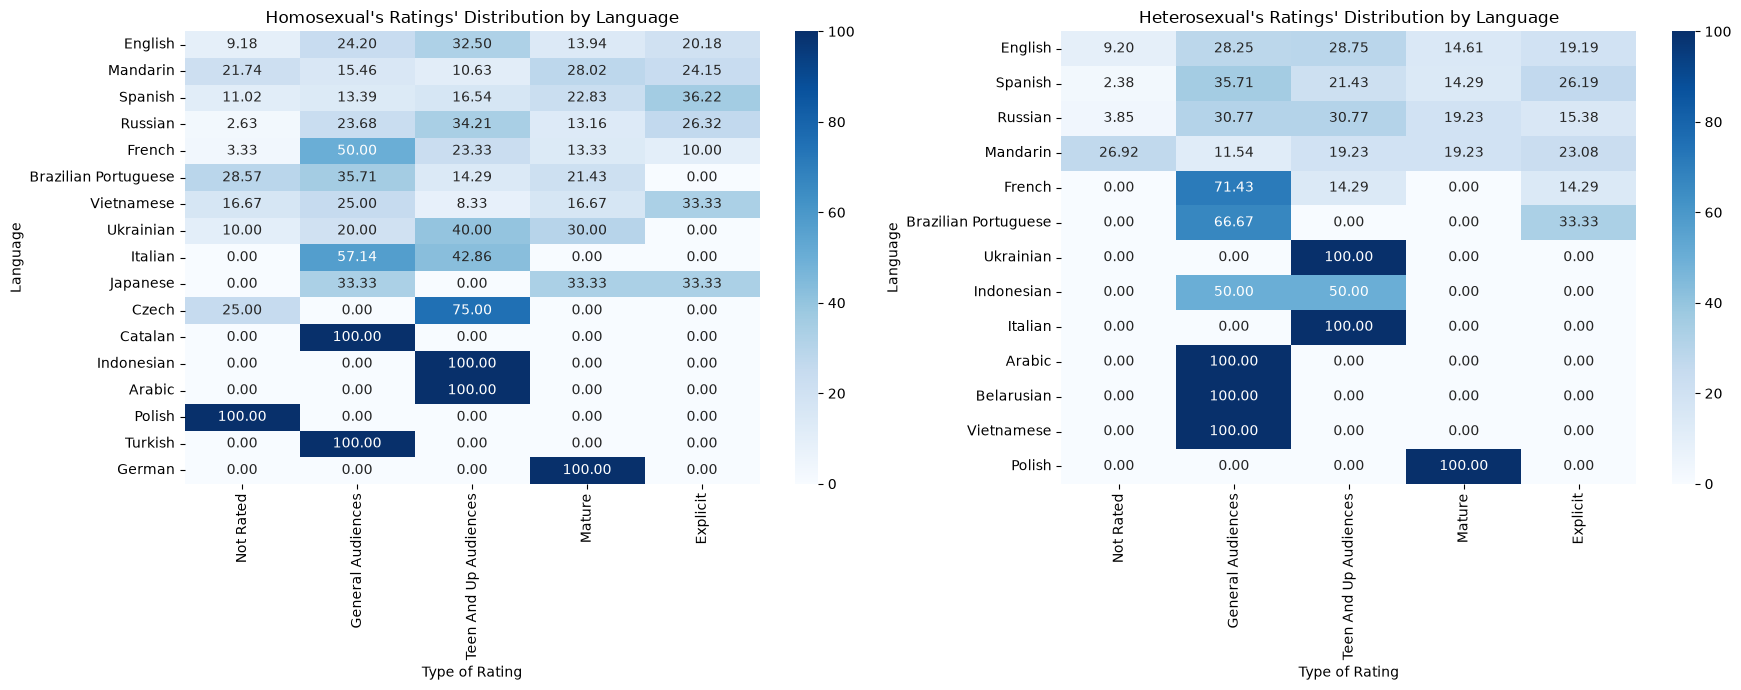

In [169]:
# Filtered by F/F + M/M
# Get numeric values
num_values_ff_mm = df_ff_mm_languages_percentages_ratings.select(["Not Rated", "General Audiences", "Teen And Up Audiences", "Mature", "Explicit"]).to_numpy()

# Create heatmap
fig, ax = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(
    num_values_ff_mm,
    ax=ax[0],
    annot=True,
    fmt=".2f",
    xticklabels=["Not Rated", "General Audiences", "Teen And Up Audiences", "Mature", "Explicit"],
    yticklabels=ff_mm_language_list,
    vmin=0,
    vmax=100,
    cmap="Blues"
)

ax[0].set_title("Homosexual's Ratings' Distribution by Language") # Add the title
ax[0].set_xlabel("Type of Rating") # Add the x-axis label
ax[0].set_ylabel("Language") # Add the y-axis label

# Filtered by F/M
# Get numeric values
num_values_fm = df_fm_languages_percentages_ratings.select(["Not Rated", "General Audiences", "Teen And Up Audiences", "Mature", "Explicit"]).to_numpy()

sns.heatmap(
    num_values_fm,
    ax=ax[1],
    annot=True,
    fmt=".2f",
    xticklabels=["Not Rated", "General Audiences", "Teen And Up Audiences", "Mature", "Explicit"],
    yticklabels=fm_language_list,
    vmin=0,
    vmax=100,
    cmap="Blues"
)

ax[1].set_title("Heterosexual's Ratings' Distribution by Language") # Add the title
ax[1].set_xlabel("Type of Rating") # Add the x-axis label
ax[1].set_ylabel("Language") # Add the y-axis label

plt.tight_layout()
plt.show()

## 2. Archive Warnings

### 2.1 Creating the Archive Warnings Datasets

In [171]:
# Filtered by F/F + M/M based on language
df_ff_mm_languages_archive_warnings = pl.DataFrame()
for ff_mm_language in ff_mm_language_list:
    ff_mm_language_archive_warnings = df_metadata.filter(
        ((pl.col("Category") == "F/F") |
        (pl.col("Category") == "M/M")) &
        (pl.col("Language") == ff_mm_language)
    ).select(pl.col("Archive Warning").value_counts()).unnest("Archive Warning").sort("Archive Warning").unpivot(index="Archive Warning", variable_name="count").pivot("Archive Warning", index="count").drop("count").with_columns(pl.lit(ff_mm_language).alias("Language")) # Filter based on language
    df_ff_mm_languages_archive_warnings = pl.concat([df_ff_mm_languages_archive_warnings, ff_mm_language_archive_warnings], how="diagonal") # Concatenate the DataFrames

df_ff_mm_languages_archive_warnings = df_ff_mm_languages_archive_warnings.select(['Language', 'Creator Chose Not To Use Archive Warnings', 'No Archive Warnings Apply', 'Underage Sex', 'Major Character Death', 'Graphic Depictions Of Violence', 'Rape/Non-Con']) # Reorder the columns
df_ff_mm_languages_archive_warnings = df_ff_mm_languages_archive_warnings.with_columns(pl.all().fill_null(strategy="zero"))

# Filtered by F/F + M/M based on language
df_fm_languages_archive_warnings = pl.DataFrame()
for fm_language in fm_language_list:
    fm_language_archive_warnings = df_metadata.filter(
        (pl.col("Category") == "F/M") & 
        (pl.col("Language") == fm_language)
    ).select(pl.col("Archive Warning").value_counts()).unnest("Archive Warning").sort("Archive Warning").unpivot(index="Archive Warning", variable_name="count").pivot("Archive Warning", index="count").drop("count").with_columns(pl.lit(fm_language).alias("Language")) # Filter based on language
    df_fm_languages_archive_warnings = pl.concat([df_fm_languages_archive_warnings, fm_language_archive_warnings], how="diagonal") # Concatenate the DataFrames

df_fm_languages_archive_warnings = df_fm_languages_archive_warnings.select(['Language', 'Creator Chose Not To Use Archive Warnings', 'No Archive Warnings Apply', 'Underage Sex', 'Major Character Death', 'Graphic Depictions Of Violence', 'Rape/Non-Con']) # Reorder the columns
df_fm_languages_archive_warnings = df_fm_languages_archive_warnings.with_columns(pl.all().fill_null(strategy="zero"))

print("Homosexual Language Archive Warnings Amount:")
df_ff_mm_languages_archive_warnings.show(17)
print("Heterosexual Language Archive Warnings Amount:")
df_fm_languages_archive_warnings.show(17)

# Calculate the Archive Warnings percentage distribution per language
df_ff_mm_languages_percentages_aw = df_ff_mm_languages_archive_warnings.with_columns((pl.exclude("Language") / pl.sum_horizontal(pl.exclude("Language")) * 100)).with_columns(pl.exclude("Language").round(2)) # Filtered based on F/F + M/M
# Calculate the Archive Warnings percentage distribution per language
df_fm_languages_percentages_aw = df_fm_languages_archive_warnings.with_columns((pl.exclude("Language") / pl.sum_horizontal(pl.exclude("Language")) * 100)).with_columns(pl.exclude("Language").round(2)) # Filtered based on F/M

print("Homosexual Language Archive Warnings Percentage Distribution:")
df_ff_mm_languages_percentages_aw.show(17)
print("Heterosexual Language Archive Warnings Percentage Distribution:")
df_fm_languages_percentages_aw.show(13)

Homosexual Language Archive Warnings Amount:


Language,Creator Chose Not To Use Archive Warnings,No Archive Warnings Apply,Underage Sex,Major Character Death,Graphic Depictions Of Violence,Rape/Non-Con
str,u32,u32,u32,u32,u32,u32
"""English""",1511,2947,210,78,153,37
"""Mandarin""",124,20,27,6,10,3
"""Spanish""",46,20,23,2,4,5
"""Russian""",9,26,0,1,0,1
"""French""",6,18,0,1,1,0
"""Brazilian Portuguese""",9,4,1,0,0,0
"""Vietnamese""",5,1,3,0,0,2
"""Ukrainian""",6,3,1,0,0,0
"""Italian""",4,3,0,0,0,0


Heterosexual Language Archive Warnings Amount:


Language,Creator Chose Not To Use Archive Warnings,No Archive Warnings Apply,Underage Sex,Major Character Death,Graphic Depictions Of Violence,Rape/Non-Con
str,u32,u32,u32,u32,u32,u32
"""English""",1156,2302,120,97,145,47
"""Spanish""",16,15,1,1,5,2
"""Russian""",7,15,0,1,0,1
"""Mandarin""",11,5,3,2,0,2
"""French""",1,4,0,0,0,0
"""Brazilian Portuguese""",2,0,0,0,0,0
"""Ukrainian""",1,1,0,0,0,0
"""Indonesian""",2,0,0,0,0,0
"""Italian""",0,1,0,0,0,0


Homosexual Language Archive Warnings Percentage Distribution:


Language,Creator Chose Not To Use Archive Warnings,No Archive Warnings Apply,Underage Sex,Major Character Death,Graphic Depictions Of Violence,Rape/Non-Con
str,f64,f64,f64,f64,f64,f64
"""English""",30.61,59.7,4.25,1.58,3.1,0.75
"""Mandarin""",65.26,10.53,14.21,3.16,5.26,1.58
"""Spanish""",46.0,20.0,23.0,2.0,4.0,5.0
"""Russian""",24.32,70.27,0.0,2.7,0.0,2.7
"""French""",23.08,69.23,0.0,3.85,3.85,0.0
"""Brazilian Portuguese""",64.29,28.57,7.14,0.0,0.0,0.0
"""Vietnamese""",45.45,9.09,27.27,0.0,0.0,18.18
"""Ukrainian""",60.0,30.0,10.0,0.0,0.0,0.0
"""Italian""",57.14,42.86,0.0,0.0,0.0,0.0


Heterosexual Language Archive Warnings Percentage Distribution:


Language,Creator Chose Not To Use Archive Warnings,No Archive Warnings Apply,Underage Sex,Major Character Death,Graphic Depictions Of Violence,Rape/Non-Con
str,f64,f64,f64,f64,f64,f64
"""English""",29.89,59.53,3.1,2.51,3.75,1.22
"""Spanish""",40.0,37.5,2.5,2.5,12.5,5.0
"""Russian""",29.17,62.5,0.0,4.17,0.0,4.17
"""Mandarin""",47.83,21.74,13.04,8.7,0.0,8.7
"""French""",20.0,80.0,0.0,0.0,0.0,0.0
"""Brazilian Portuguese""",100.0,0.0,0.0,0.0,0.0,0.0
"""Ukrainian""",50.0,50.0,0.0,0.0,0.0,0.0
"""Indonesian""",100.0,0.0,0.0,0.0,0.0,0.0
"""Italian""",0.0,100.0,0.0,0.0,0.0,0.0


### 2.2 Visualizing the Archive Warnings Datasets

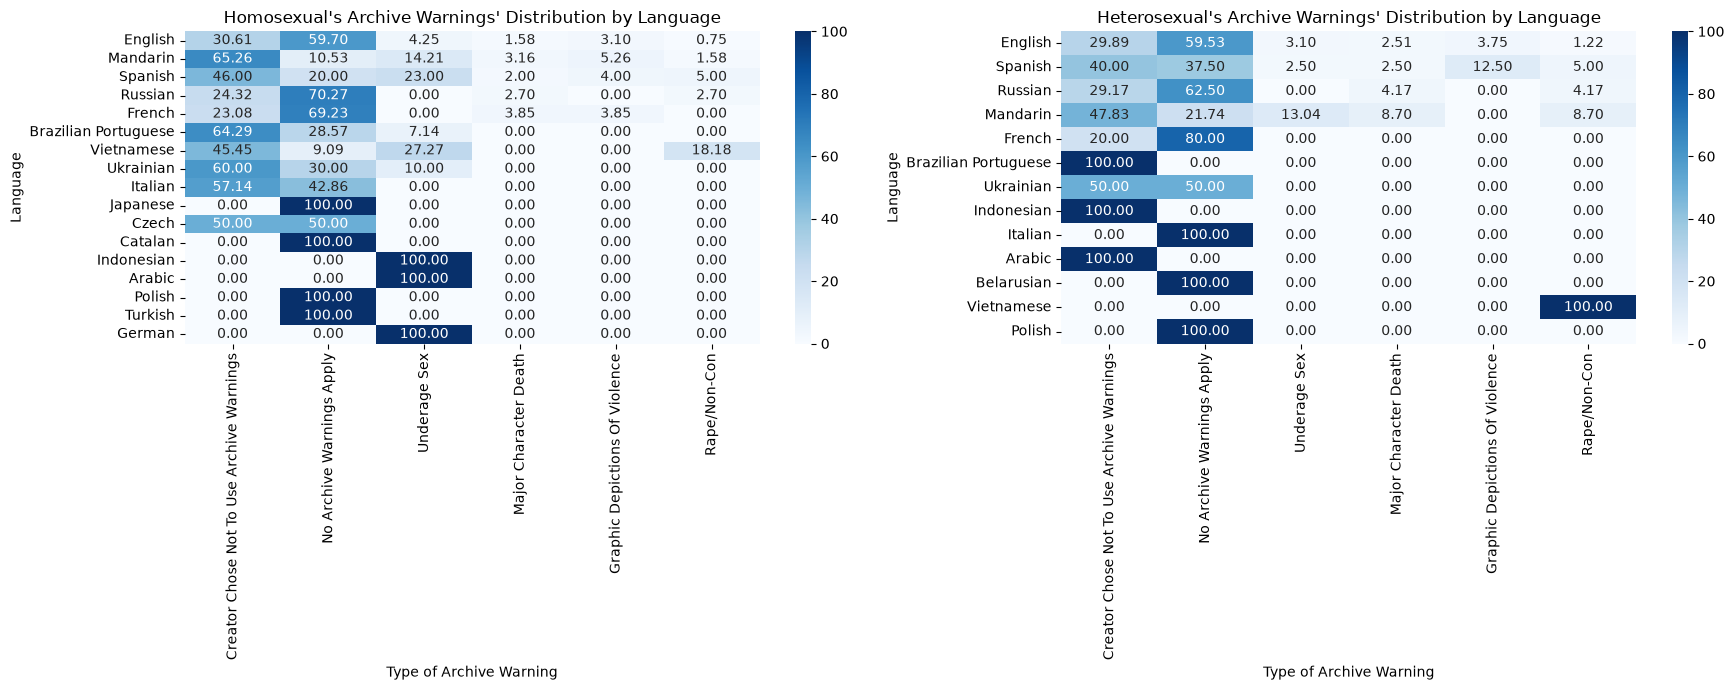

In [173]:
# Filtered by F/F + M/M
# Get numeric values
num_values_ff_mm = df_ff_mm_languages_percentages_aw.select(['Creator Chose Not To Use Archive Warnings', 'No Archive Warnings Apply', 'Underage Sex', 'Major Character Death', 'Graphic Depictions Of Violence', 'Rape/Non-Con']).to_numpy()

# Create heatmap
fig, ax = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(
    num_values_ff_mm,
    ax=ax[0],
    annot=True,
    fmt=".2f",
    xticklabels=['Creator Chose Not To Use Archive Warnings', 'No Archive Warnings Apply', 'Underage Sex', 'Major Character Death', 'Graphic Depictions Of Violence', 'Rape/Non-Con'],
    yticklabels=ff_mm_language_list,
    vmin=0,
    vmax=100,
    cmap="Blues"
)

ax[0].set_title("Homosexual's Archive Warnings' Distribution by Language") # Add the title
ax[0].set_xlabel("Type of Archive Warning") # Add the x-axis label
ax[0].set_ylabel("Language") # Add the y-axis label

# Filtered by F/M
# Get numeric values
num_values_fm = df_fm_languages_percentages_aw.select(['Creator Chose Not To Use Archive Warnings', 'No Archive Warnings Apply', 'Underage Sex', 'Major Character Death', 'Graphic Depictions Of Violence', 'Rape/Non-Con']).to_numpy()

sns.heatmap(
    num_values_fm,
    ax=ax[1],
    annot=True,
    fmt=".2f",
    xticklabels=['Creator Chose Not To Use Archive Warnings', 'No Archive Warnings Apply', 'Underage Sex', 'Major Character Death', 'Graphic Depictions Of Violence', 'Rape/Non-Con'],
    yticklabels=fm_language_list,
    vmin=0,
    vmax=100,
    cmap="Blues"
)

ax[1].set_title("Heterosexual's Archive Warnings' Distribution by Language") # Add the title
ax[1].set_xlabel("Type of Archive Warning") # Add the x-axis label
ax[1].set_ylabel("Language") # Add the y-axis label

plt.tight_layout()
plt.show()

## 3. Additional Tags

### 3.1 Creating the Additional Tags Datasets

In [174]:
# Read the CSV file
df_annotated_tags_fandom_category = pl.read_csv("./data/df_annotated_tags_fandom_category.csv")
df_add_tag_annotation = pl.read_csv("./data/df_additional_tag_annotations.csv")
df_annotated_tags_fandom_category.show()
df_add_tag_annotation.show()

Fandom,Category,Additional Tags,Freq,Character,Narrative,Porn,Kink
str,str,str,i64,str,str,str,str
"""Avatar: The Last Airbender (Ca…","""F/M""","""!!TW!!""",1,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""
"""Avatar: The Last Airbender (Ca…","""F/M""","""""Has she always been good at t…",1,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""
"""Avatar: The Last Airbender (Ca…","""F/M""","""""I love the smell of incest 😍😍…",1,"""No Character""","""No Narrative""","""Is Porn""","""Not Kink"""
"""Spider-Man: Spider-Verse (Sony…","""F/M""","""""I loved her to the point of i…",1,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""
"""DC's Legends of Tomorrow (TV)""","""F/F""","""""Mayday Mayday!""""",1,"""No Character""","""Event-related/Action""","""Not Porn""","""Not Kink"""


Additional Tags,Character,Narrative,Porn,Kink
str,str,str,str,str
"""Fluff""","""No Character""","""Theme/Genre""","""Not Porn""","""Not Kink"""
"""Angst""","""No Character""","""Theme/Genre""","""Not Porn""","""Not Kink"""
"""AvaLance""","""No Character""","""Plot""","""Not Porn""","""Not Kink"""
"""Hurt/Comfort""","""Emotion/Mental State""","""No Narrative""","""Not Porn""","""Not Kink"""
"""Angst with a Happy Ending""","""No Character""","""Theme/Genre""","""Not Porn""","""Not Kink"""


In [176]:
def label_freq(df):
    """
    Calculates the frequency of the annotations.

    Parameter:
        df (DataFrame): Filtered DataFrame.
    Returns:
        df_label_freq (DataFrame): Contains the frequency of the annotations.
    """
    # Add the frequency of the annotations based on unique additional tags
    categories = ["Character", "Narrative", "Porn", "Kink"]

    df_unique_values = pl.DataFrame()
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[0]).value_counts()).unnest(categories[0]).rename({"Character": "Label"})])
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[1]).value_counts()).unnest(categories[1]).rename({"Narrative": "Label"})])
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[2]).value_counts()).unnest(categories[2]).rename({"Porn": "Label"})])
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[3]).value_counts()).unnest(categories[3]).rename({"Kink": "Label"})])
    df_unique_values = df_unique_values.rename({"count": "Unique Additional Tags Frequency"})

    # Turn into lists
    char_list = ['No Character', 'Biography', 'Physical Feature', 'Emotion/Mental State', 'Relationship', "Personality"]
    nar_list = ['No Narrative', 'Plot', 'Event-related/Action', 'Theme/Genre', 'WorldSetting', 'Narrative Methods', 'Format']
    porn_list = ['Not Porn', 'Is Porn']
    kink_list = ['Not Kink', 'Is Kink']

    # Append the frequency of the annotations based on total additional tags
    df_freq_count = pl.DataFrame()
    for char_label in char_list:
        df_temp_char = pl.DataFrame({
            "Label": char_label,
            "Freq": df.filter(pl.col("Character") == char_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_char])
    for nar_label in nar_list:
        df_temp_nar = pl.DataFrame({
            "Label": nar_label,
            "Freq": df.filter(pl.col("Narrative") == nar_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_nar])
    for porn_label in porn_list:
        df_temp_porn = pl.DataFrame({
            "Label": porn_label,
            "Freq": df.filter(pl.col("Porn") == porn_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_porn])
    for kink_label in kink_list:
        df_temp_kink = pl.DataFrame({
            "Label": kink_label,
            "Freq": df.filter(pl.col("Kink") == kink_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_kink])
    
    df_freq_count = df_freq_count.rename({"Freq": "Total Additional Tags Frequency"})

    labels = df_freq_count.to_series(0)
    df_label_freq = pl.concat([df_unique_values, df_freq_count], how='align')
    df_label_freq = df_label_freq.sort(pl.col("Total Additional Tags Frequency"), descending=True)
    
    return df_label_freq